# Bangkok CCTV Images — Exploratory Data Analysis

2110403 DSDE-CEDT project (2026/1). Raw dataset: `cctv_images/<camera_id>/<camera_id>_<name>_<location>_<YYYYMMDD>_<HHMMSS>.jpg`.

Steps:
1. Parse filenames into metadata and compute cheap per-image quality features (`pipeline (เก้อ)/extract_features.py`).
2. Coverage: cameras, days, hours, capture interval, gaps/outages.
3. Image properties: resolution, file size.
4. Data quality: placeholder frames, test patterns, dark/blurred/stale frames, clock-overlay mismatch.
5. Lighting by time of day.
6. Cleaning rules + clean table for the next stage (vehicle detection etc.).

In [1]:
from pathlib import Path
import subprocess, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()   # repo root
DATA_DIR = ROOT / "data/cctv_images"      # <-- set to the extracted zip folder
FEAT_CSV = ROOT / "data_out/features.csv"
OUT_DIR  = ROOT / "data_out"; OUT_DIR.mkdir(exist_ok=True)

if not FEAT_CSV.exists():
    subprocess.run([sys.executable, str(ROOT / "pipeline/extract_features.py"), str(DATA_DIR), str(FEAT_CSV)], check=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
df = pd.read_csv(FEAT_CSV, parse_dates=["timestamp"], dtype={"ahash": str, "md5": str}).sort_values(["camera_id", "timestamp"]).reset_index(drop=True)
df["date"] = df.timestamp.dt.date
df["hour"] = df.timestamp.dt.hour
df["slot"] = df.timestamp.dt.floor("10min")
print(df.shape); df.head(3)

(61319, 27)


,path,folder,filename,parse_ok,camera_id,camera_name,location,timestamp,file_size,md5,...,dark_frac,bright_frac,r_mean,g_mean,b_mean,ahash,read_ok,date,hour,slot
0,/private/tmp/claude-501/-Users-fifaak-Library-...,11,11_ใกล้ซอยราชวิถี-6-ถนนราชวิถี_รถมาจากอนุสาวรี...,True,11,ใกล้ซอยราชวิถี-6-ถนนราชวิถี,รถมาจากอนุสาวรีย์ชัยสมรภูม,2026-08-25 06:15:08,29540,4efc205aa78b59c928917c9fd4fd820d,...,0.000313,0.000625,104.395882,100.995781,100.459892,1c3c3e3e2e4e86dc,True,2026-08-25,6,2026-08-25 06:10:00
1,/private/tmp/claude-501/-Users-fifaak-Library-...,11,11_ใกล้ซอยราชวิถี-6-ถนนราชวิถี_รถมาจากอนุสาวรี...,True,11,ใกล้ซอยราชวิถี-6-ถนนราชวิถี,รถมาจากอนุสาวรีย์ชัยสมรภูม,2026-08-25 06:25:08,31977,6a940206264b127d81b58073eb327de0,...,0.000260,0.006615,106.917656,107.021461,103.102913,0c1c3e362246cefc,True,2026-08-25,6,2026-08-25 06:20:00
2,/private/tmp/claude-501/-Users-fifaak-Library-...,11,11_ใกล้ซอยราชวิถี-6-ถนนราชวิถี_รถมาจากอนุสาวรี...,True,11,ใกล้ซอยราชวิถี-6-ถนนราชวิถี,รถมาจากอนุสาวรีย์ชัยสมรภูม,2026-08-25 06:35:09,31442,9d5af8b5065c4976830999681ed77fcb,...,0.000469,0.001458,104.696877,105.015572,103.260674,1c3e363e3e4ec6c6,True,2026-08-25,6,2026-08-25 06:30:00


## 1. Overview & parsing checks

In [2]:
summary = {
    "images": len(df),
    "cameras": df.camera_id.nunique(),
    "filename parse failures": int((~df.parse_ok).sum()),
    "unreadable images": int((~df.read_ok).sum()),
    "folder != camera_id": int((df.folder.astype(str) != df.camera_id.astype(str)).sum()),
    "exact duplicate files (md5)": int(df.md5.duplicated().sum()),
    "duplicate (camera, timestamp)": int(df.duplicated(["camera_id", "timestamp"]).sum()),
    "first timestamp": df.timestamp.min(), "last timestamp": df.timestamp.max(),
    "total size (GB)": round(df.file_size.sum() / 1e9, 2),
    "unique camera names": df.drop_duplicates("camera_id").camera_name.nunique(),
}
pd.Series(summary, dtype=object).to_frame("value")

,value
images,61319
cameras,100
filename parse failures,0
unreadable images,0
folder != camera_id,0
exact duplicate files (md5),0
"duplicate (camera, timestamp)",0
first timestamp,2026-08-25 06:00:00
last timestamp,2026-08-31 21:01:19
total size (GB),1.58


Camera names are truncated (~30 Thai chars) and not unique (88 names for 100 cameras) → **use `camera_id` as key**, not name.
Names still carry useful info: intersection (`แยก...`), road side (`ด้าน...`), direction (`รถมาจาก` = inbound / `รถมุ่งหน้าไป` = outbound).

In [3]:
cams = df.drop_duplicates("camera_id")[["camera_id", "camera_name", "location"]].copy()
cams["is_intersection"] = cams.camera_name.str.contains("แยก")
cams["direction"] = np.select([cams.location.str.contains("รถมาจาก"), cams.location.str.contains("มุ่งหน้า")],
                              ["from (inbound)", "towards (outbound)"], "other")
display(cams.direction.value_counts().to_frame())
display(cams.is_intersection.value_counts().to_frame())
cams.to_csv(OUT_DIR / "cameras.csv", index=False)

,count
direction,
from (inbound),57
other,32
towards (outbound),11


,count
is_intersection,
False,55
True,45


## 2. Temporal coverage

,count,mean,std,min,25%,50%,75%,max
images/camera,100.0,613.19,3.521062,604.0,612.0,613.0,614.0,631.0


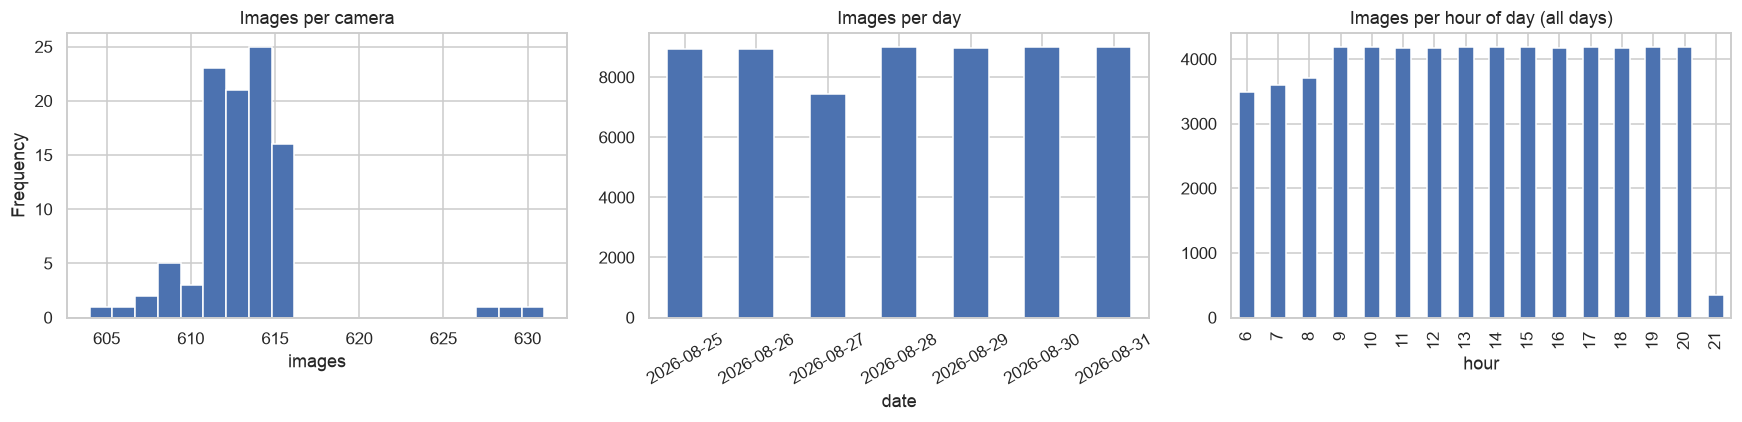

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
per_cam = df.groupby("camera_id").size()
per_cam.plot.hist(bins=20, ax=ax[0], title="Images per camera"); ax[0].set_xlabel("images")
df.groupby("date").size().plot.bar(ax=ax[1], title="Images per day", rot=30)
df.groupby("hour").size().plot.bar(ax=ax[2], title="Images per hour of day (all days)")
plt.tight_layout(); per_cam.describe().to_frame("images/camera").T

- 7 days: **2026-08-25 → 2026-08-31**, capture window **06:00–21:00** only (no night after 21:00, no 21–06 data).
- ~613 images/camera (604–631), consistent with the brief.
- 2026-08-27 has fewer images → outage (below).

{0.01: 9.58, 0.05: 9.92, 0.5: 10.0, 0.95: 10.15, 0.99: 90.0}


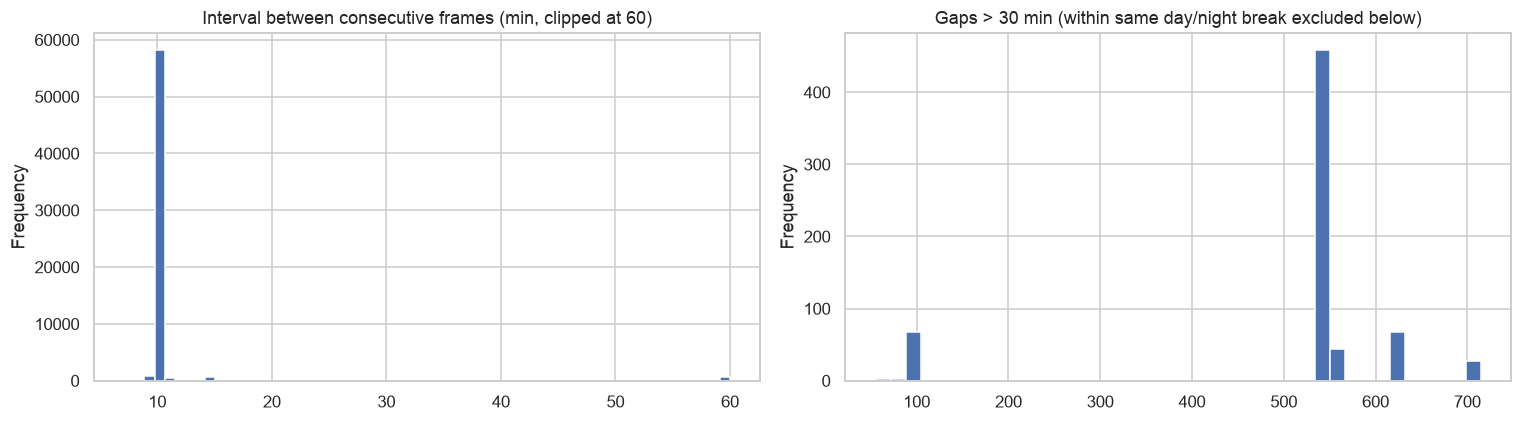

In [5]:
gap = df.groupby("camera_id").timestamp.diff().dt.total_seconds() / 60
df["gap_min"] = gap
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
gap.clip(upper=60).plot.hist(bins=60, ax=ax[0], title="Interval between consecutive frames (min, clipped at 60)")
gap[gap > 30].plot.hist(bins=40, ax=ax[1], title="Gaps > 30 min (within same day/night break excluded below)")
plt.tight_layout()
print(gap.quantile([.01, .05, .5, .95, .99]).round(2).to_dict())

Sampling is **every ~10 minutes** per camera (median 10.0 min). Large gaps = overnight break (21:00→06:00) + outages.

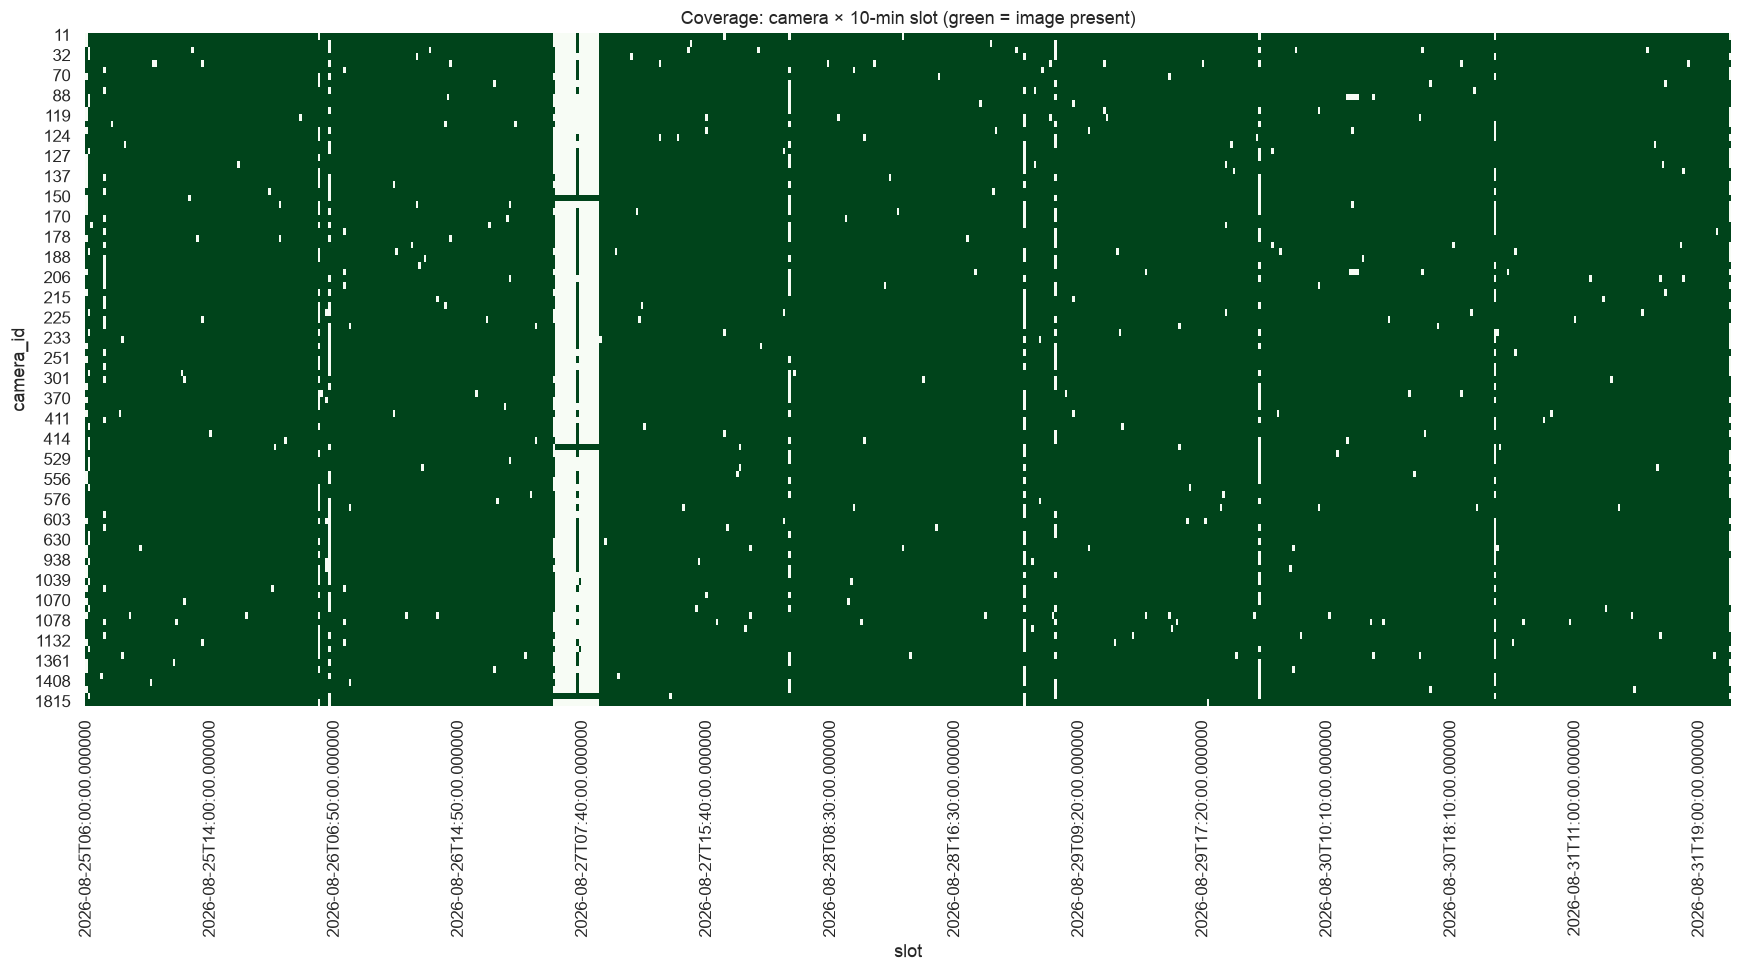

In [6]:
cov = df.groupby(["camera_id", "slot"]).size().unstack(fill_value=0).clip(upper=1)
fig, ax = plt.subplots(figsize=(16, 9))
sns.heatmap(cov, cmap="Greens", cbar=False, ax=ax, xticklabels=48)
ax.set_title("Coverage: camera × 10-min slot (green = image present)"); plt.tight_layout()

,cameras_reporting
slot,
2026-08-25 06:00:00,64
2026-08-25 06:10:00,78
2026-08-25 07:10:00,75
2026-08-25 21:00:00,53
2026-08-26 06:30:00,46
2026-08-26 21:00:00,57
2026-08-27 06:00:00,3
2026-08-27 06:10:00,3
2026-08-27 06:20:00,3


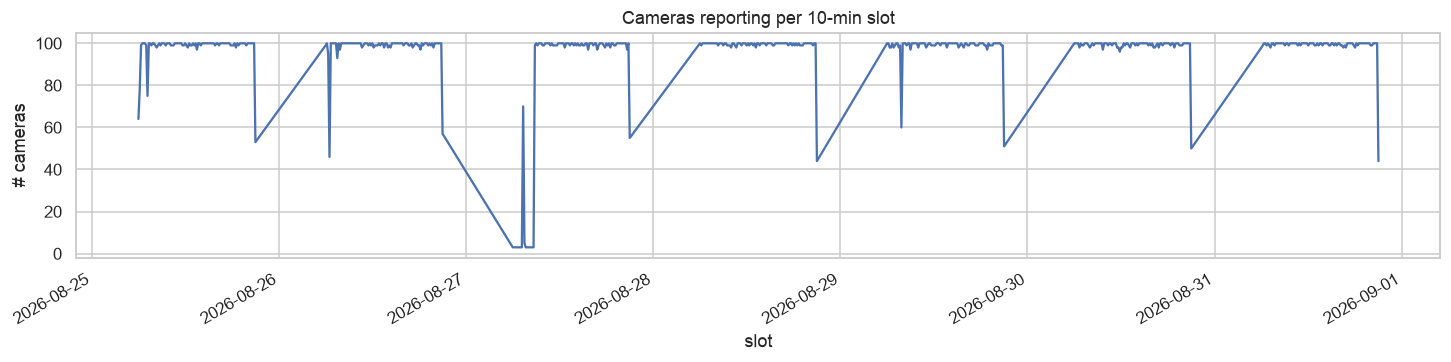

In [7]:
slot_cov = df.groupby("slot").camera_id.nunique()
outage = slot_cov[slot_cov < 90]
fig, ax = plt.subplots(figsize=(16, 3))
slot_cov.plot(ax=ax, title="Cameras reporting per 10-min slot"); ax.set_ylabel("# cameras")
outage.to_frame("cameras_reporting")

**System-wide outage: 2026-08-27 06:00–08:50** — only 3 cameras reported (except one slot at 07:20).
Other dips are first/last slots of each day (06:00, 21:00) → partial slots.
Implication: exclude/flag 27-Aug morning when comparing days; aggregate by hour with per-camera normalisation.

## 3. Image properties

,,images,cameras,mean_brightness
width,height,,,
246,205,33,2,124.793411
348,261,608,1,110.878602
352,288,60174,99,114.541735
400,266,504,100,255.000000


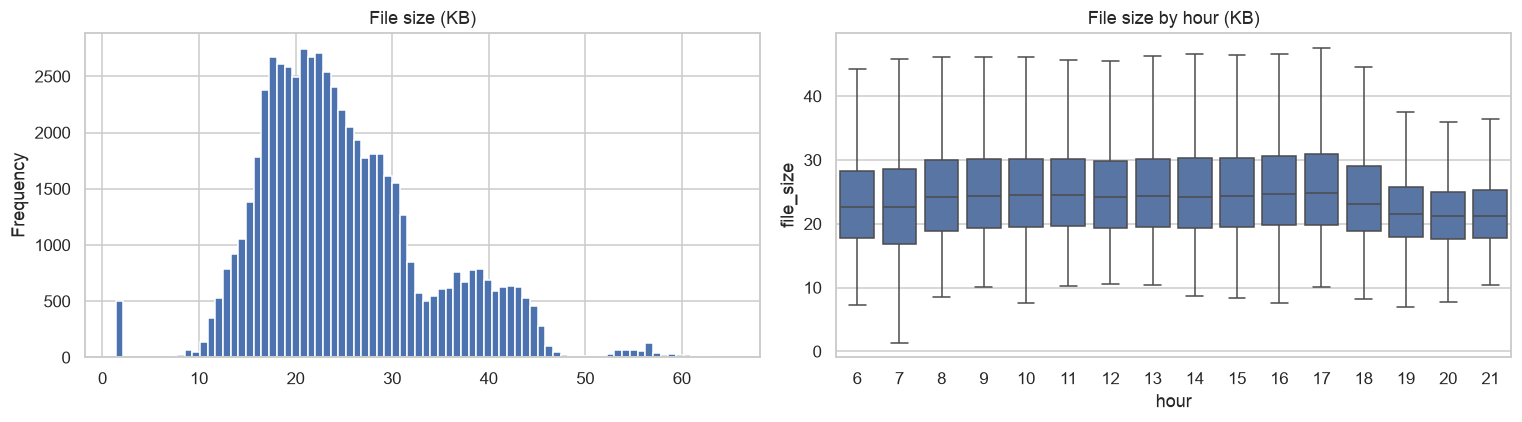

In [8]:
res = df.groupby(["width", "height"]).agg(images=("path", "size"), cameras=("camera_id", "nunique"),
                                         mean_brightness=("brightness", "mean"))
display(res)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(df.file_size / 1024).plot.hist(bins=80, ax=ax[0], title="File size (KB)")
sns.boxplot(data=df, x="hour", y=df.file_size / 1024, ax=ax[1], showfliers=False); ax[1].set_title("File size by hour (KB)")
plt.tight_layout()

- **352×288 (CIF)** = normal frames (98%).
- **400×266** = 504 frames, all pure white → *placeholder* returned by BMA site. They hit **all cameras in the same slot** (e.g. 26-Aug 07:40, 28-Aug 07:50 = 100/100 cams) → server-side/scraper failure, not individual cameras.
- **246×205** = 33 frames from cams 432, 1804 → *GStreamer colour-bar test pattern* (`gst-launch`).
- **348×261** = camera 395 only (all its frames) → valid, needs resize to common size.
- JPEG size is a cheap proxy for scene complexity (more vehicles/texture → larger). Drops in the evening as scenes darken.

## 4. Data quality / anomaly detection

In [9]:
df["prev_ahash"] = df.groupby("camera_id").ahash.shift()
def ham(a, b):
    return np.nan if pd.isna(b) else bin(int(a, 16) ^ int(b, 16)).count("1")
df["ahash_dist_prev"] = [ham(a, b) for a, b in zip(df.ahash, df.prev_ahash)]

flags = pd.DataFrame({
    "placeholder_white": (df.width == 400) & (df.height == 266) | (df.bright_frac > 0.9),
    "test_pattern":      (df.width == 246) & (df.height == 205),
    "very_dark":         df.dark_frac > 0.6,
    "blurry":            (df.sharpness < 100) & (df.bright_frac <= 0.9),
    "stale_repeat":      df.ahash_dist_prev == 0,   # visually identical to previous frame
})
df = df.join(flags)
df["invalid"] = df.placeholder_white | df.test_pattern
q = flags.sum().to_frame("images"); q["%"] = (q.images / len(df) * 100).round(2)
q["cameras"] = [df.loc[flags[c], "camera_id"].nunique() for c in flags]
display(q)
df[df.placeholder_white].slot.value_counts().head(8).to_frame("cameras_with_placeholder")

,images,%,cameras
placeholder_white,504,0.82,100
test_pattern,33,0.05,2
very_dark,13,0.02,2
blurry,69,0.11,5
stale_repeat,2418,3.94,92


,cameras_with_placeholder
slot,
2026-08-26 07:40:00,100
2026-08-28 07:50:00,100
2026-08-30 08:40:00,73
2026-08-27 07:20:00,69
2026-08-29 07:50:00,55
2026-08-31 07:20:00,45
2026-08-31 07:30:00,17
2026-08-26 07:50:00,11


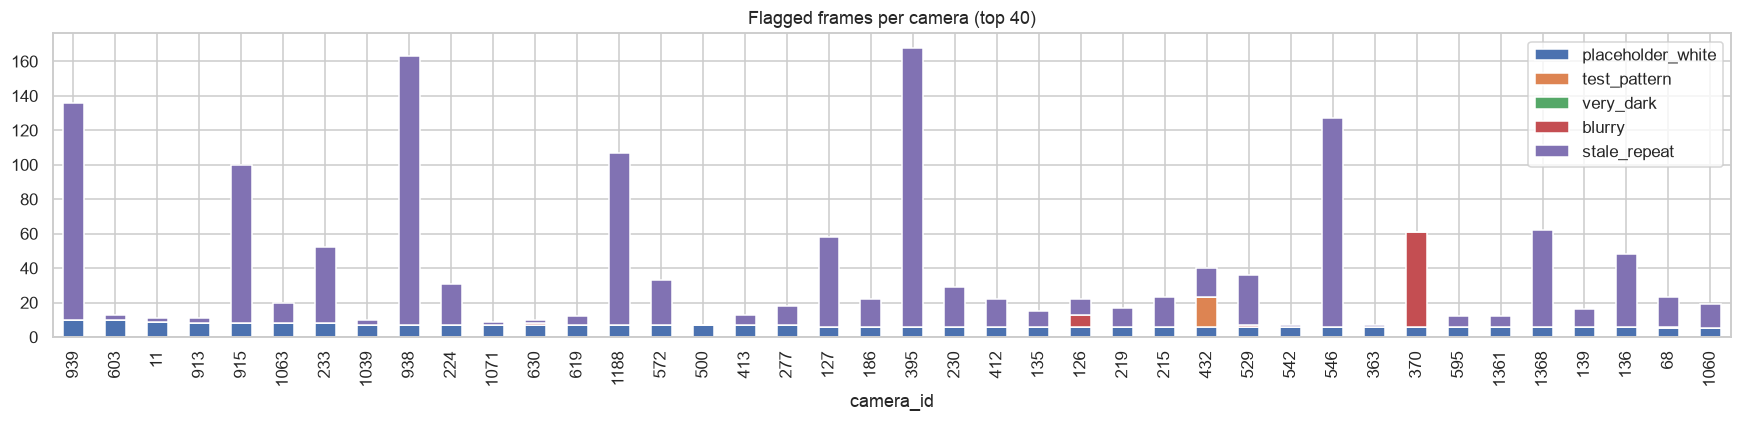

In [10]:
top = df.groupby("camera_id")[list(flags.columns)].sum()
top = top[top.sum(axis=1) > 0].sort_values("placeholder_white", ascending=False)
fig, ax = plt.subplots(figsize=(16, 4))
top.head(40).plot.bar(stacked=True, ax=ax, title="Flagged frames per camera (top 40)"); plt.tight_layout()

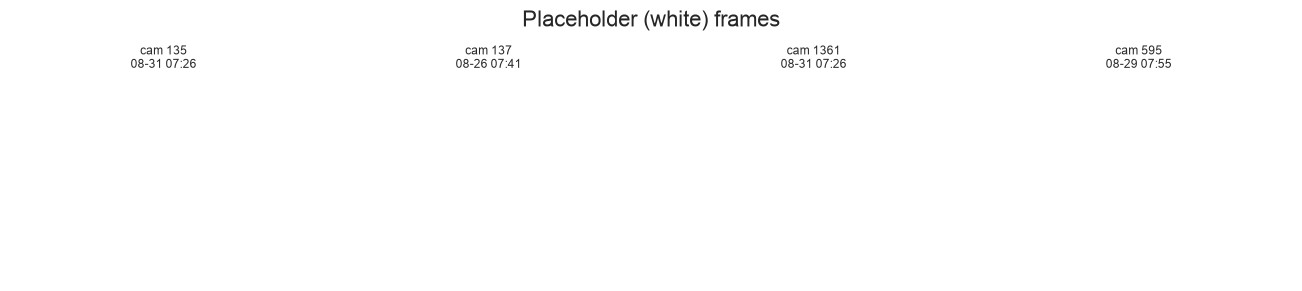

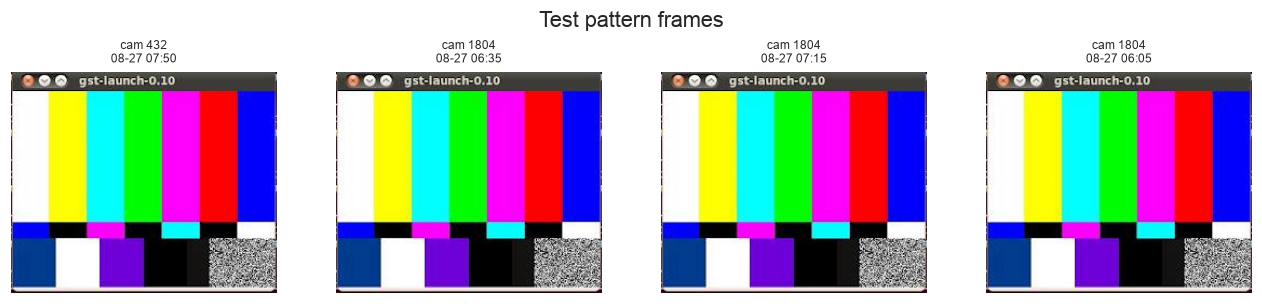

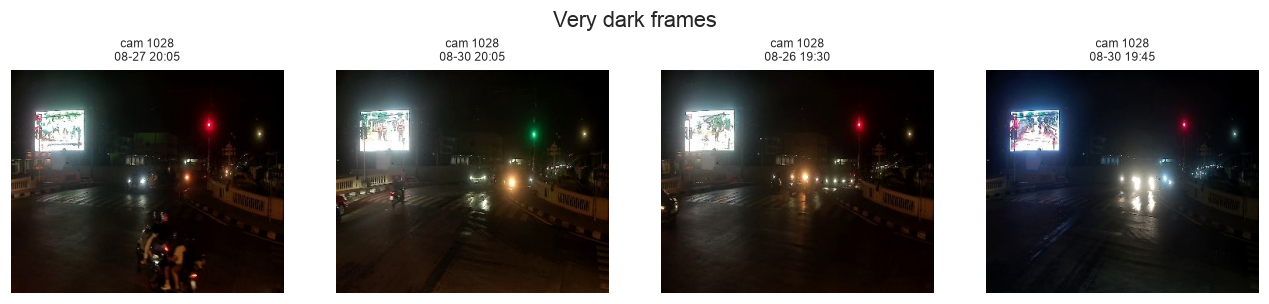

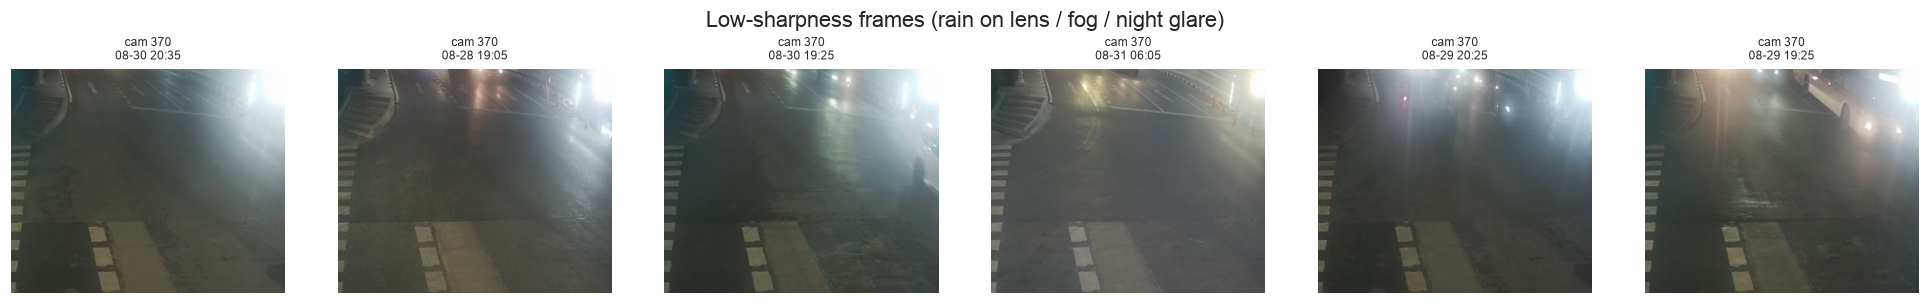

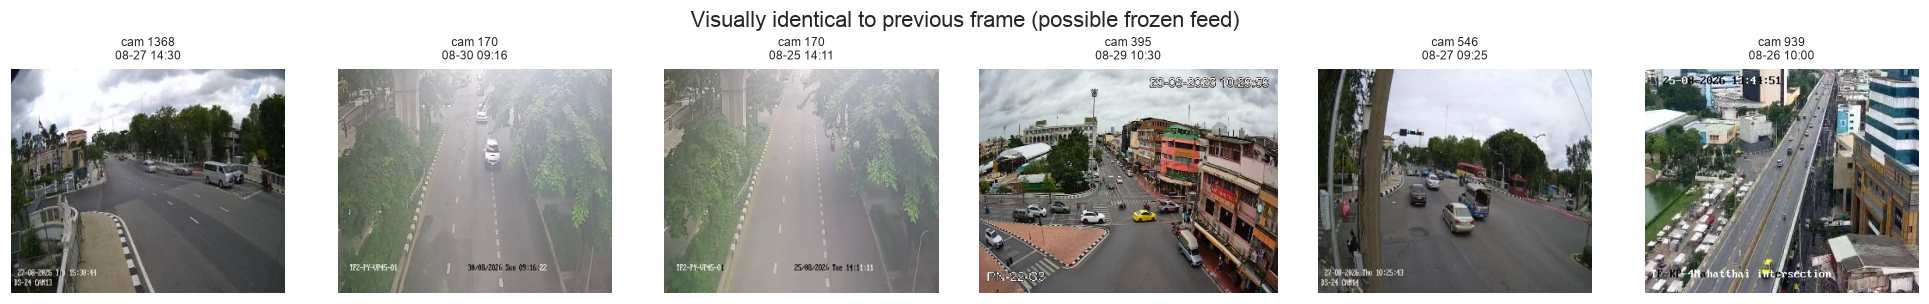

In [11]:
def show(rows, title, n=8):
    rows = rows.sample(min(n, len(rows)), random_state=0) if len(rows) > n else rows
    fig, axes = plt.subplots(1, len(rows), figsize=(3 * len(rows), 2.8))
    axes = np.atleast_1d(axes)
    for a, (_, r) in zip(axes, rows.iterrows()):
        a.imshow(Image.open(r.path)); a.axis("off"); a.set_title(f"cam {r.camera_id}\n{r.timestamp:%m-%d %H:%M}", fontsize=8)
    fig.suptitle(title); plt.tight_layout()

show(df[df.placeholder_white], "Placeholder (white) frames", 4)
show(df[df.test_pattern], "Test pattern frames", 4)
show(df[df.very_dark], "Very dark frames", 4)
show(df[df.blurry & ~df.invalid], "Low-sharpness frames (rain on lens / fog / night glare)", 6)
show(df[df.stale_repeat & ~df.invalid], "Visually identical to previous frame (possible frozen feed)", 6)

**On-screen clock (OSD) is unreliable**: e.g. cam 395 overlay shows `00:12` while filename says 15:00; some cameras show `1970`.
→ always use **filename timestamp** (scrape time) as ground truth; do not OCR the overlay for time.

## 5. Lighting & colour by time of day (valid frames only)

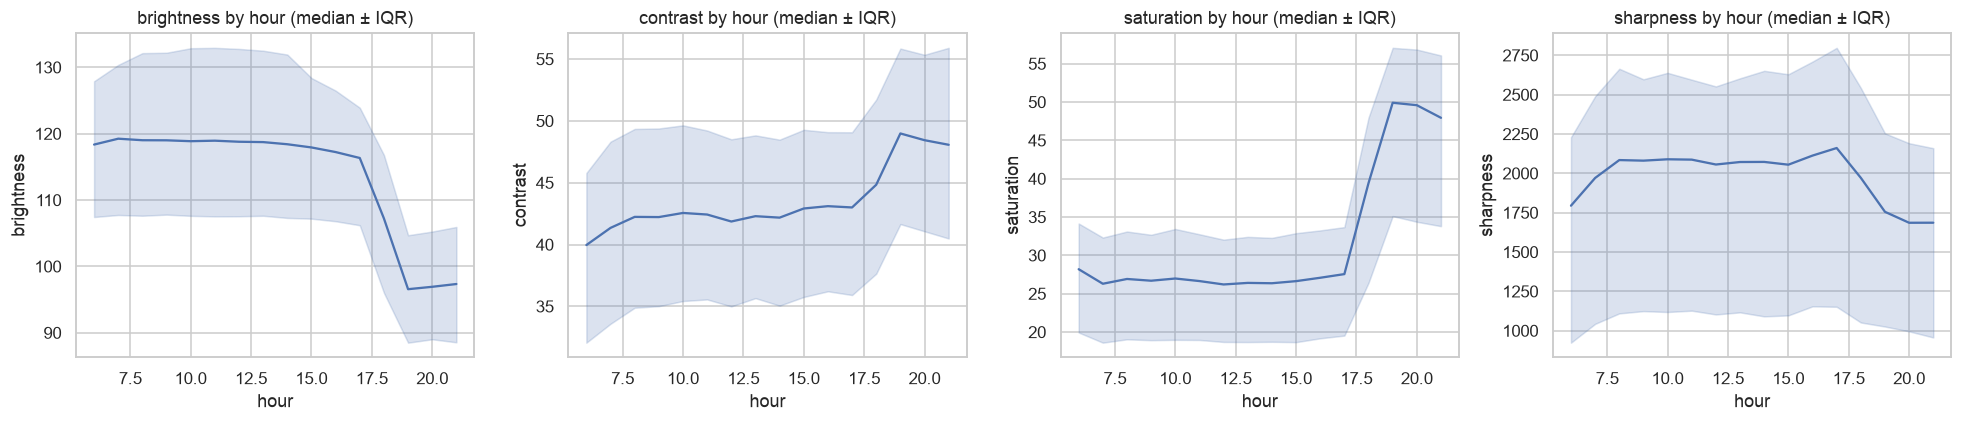

In [12]:
v = df[~df.invalid]
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col in zip(ax, ["brightness", "contrast", "saturation", "sharpness"]):
    sns.lineplot(data=v, x="hour", y=col, errorbar=("pi", 50), ax=a); a.set_title(f"{col} by hour (median ± IQR)")
plt.tight_layout()

Text(0.5, 1.0, 'Mean brightness: day × hour')

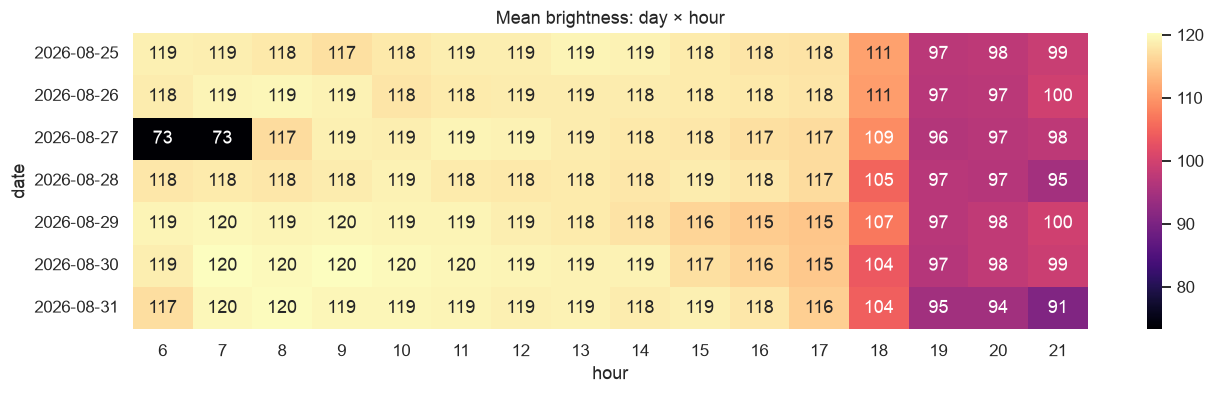

In [13]:
piv = v.pivot_table(index="date", columns="hour", values="brightness", aggfunc="mean")
fig, ax = plt.subplots(figsize=(14, 3.5))
sns.heatmap(piv, cmap="magma", annot=True, fmt=".0f", ax=ax); ax.set_title("Mean brightness: day × hour")

- Brightness flat ~119 from 07–17h, drops after 18h (sunset ~18:20 in late Aug) to ~97 at 19–21h.
- Night frames: lower sharpness, headlight glare, wet-road reflections → detection models will be weaker after 18:30.
- Day-to-day differences in the afternoon/evening hint at weather (rain → darker, lower contrast). Can join with rainfall data (scraping task).

In [14]:
v = v.assign(light=np.where(v.brightness < 90, "dark", "day"))
pd.crosstab(v.hour, v.light, normalize="index").round(2).T

hour,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
light,,,,,,,,,,,,,,,,
dark,0.02,0.01,0.01,0.01,0.02,0.02,0.02,0.02,0.02,0.02,0.02,0.03,0.12,0.3,0.28,0.3
day,0.98,0.99,0.99,0.99,0.98,0.98,0.98,0.98,0.98,0.98,0.98,0.97,0.88,0.7,0.72,0.7


## 6. Per-camera profile

,images,brightness,contrast,sharpness,kb
count,100.0,100.0,100.0,100.0,100.0
mean,607.8,117.7,42.2,2007.5,25.6
std,3.3,15.5,9.2,1243.9,8.5
min,600.0,79.2,22.4,254.1,12.2
25%,606.0,106.8,36.0,1123.5,19.4
50%,608.0,112.2,41.6,1730.0,24.0
75%,610.0,124.2,48.2,2386.6,29.3
max,627.0,150.1,69.9,5633.8,55.9


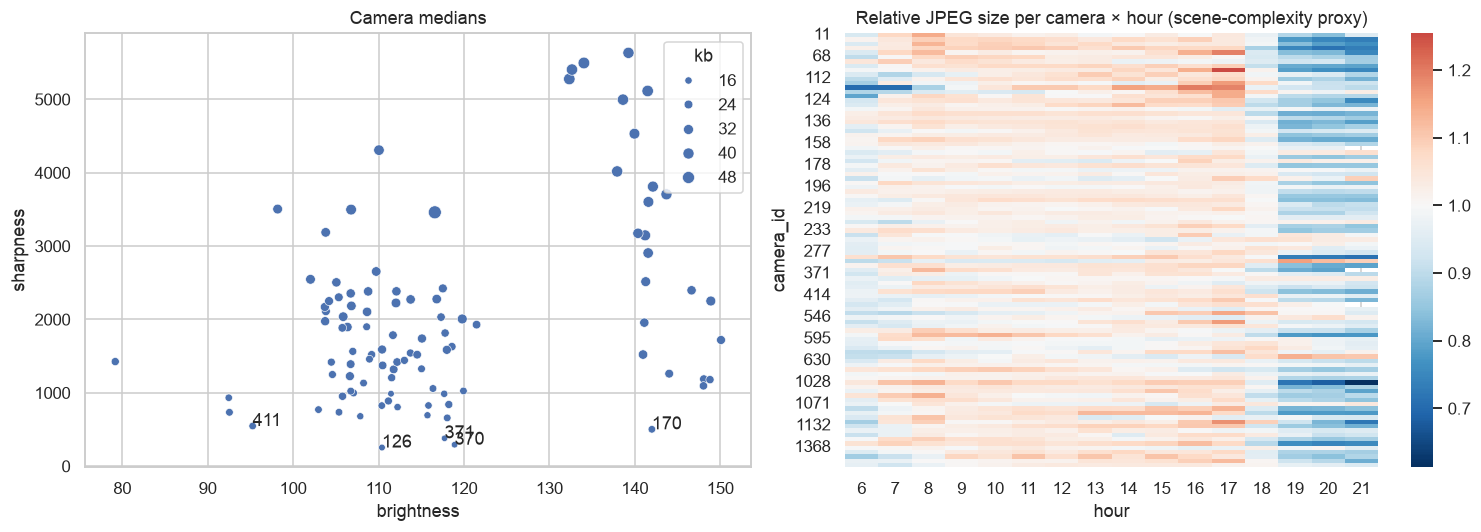

In [15]:
prof = v.groupby("camera_id").agg(images=("path", "size"), brightness=("brightness", "median"),
                                  contrast=("contrast", "median"), sharpness=("sharpness", "median"),
                                  kb=("file_size", lambda s: s.median() / 1024))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=prof, x="brightness", y="sharpness", size="kb", ax=ax[0]); ax[0].set_title("Camera medians")
for cid, r in prof.nsmallest(5, "sharpness").iterrows(): ax[0].annotate(cid, (r.brightness, r.sharpness))
hour_kb = v.pivot_table(index="camera_id", columns="hour", values="file_size", aggfunc="median")
sns.heatmap(hour_kb.div(hour_kb.mean(axis=1), axis=0), cmap="RdBu_r", center=1, ax=ax[1])
ax[1].set_title("Relative JPEG size per camera × hour (scene-complexity proxy)"); plt.tight_layout()
prof.describe().round(1)

## 7. Sample grid (random valid frames)

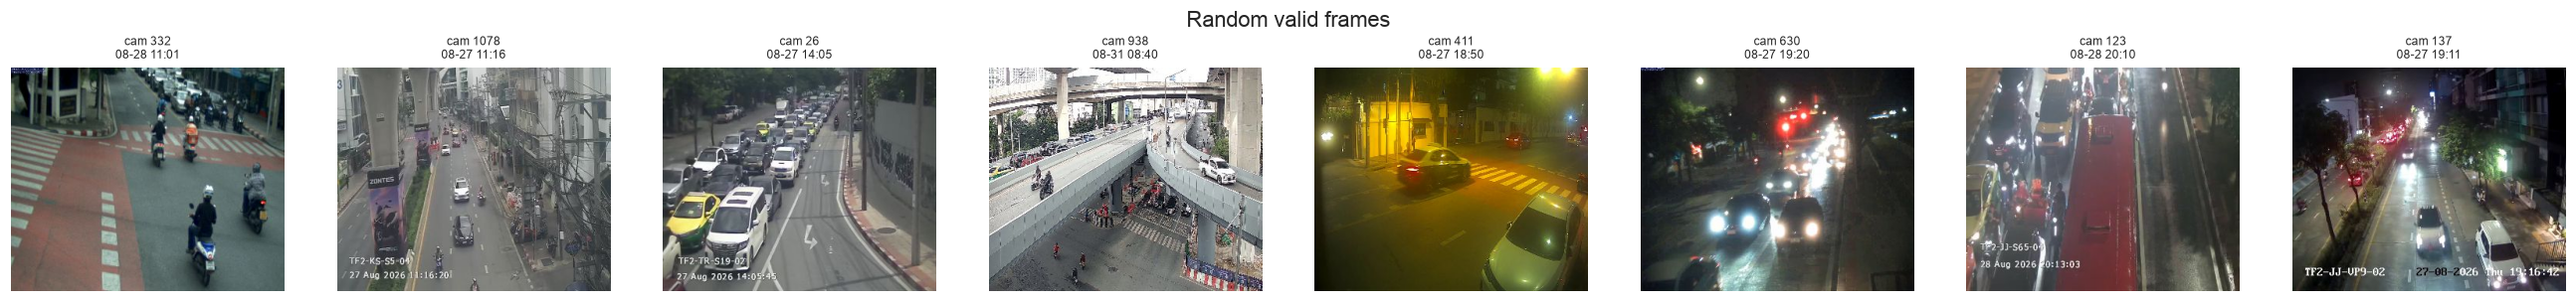

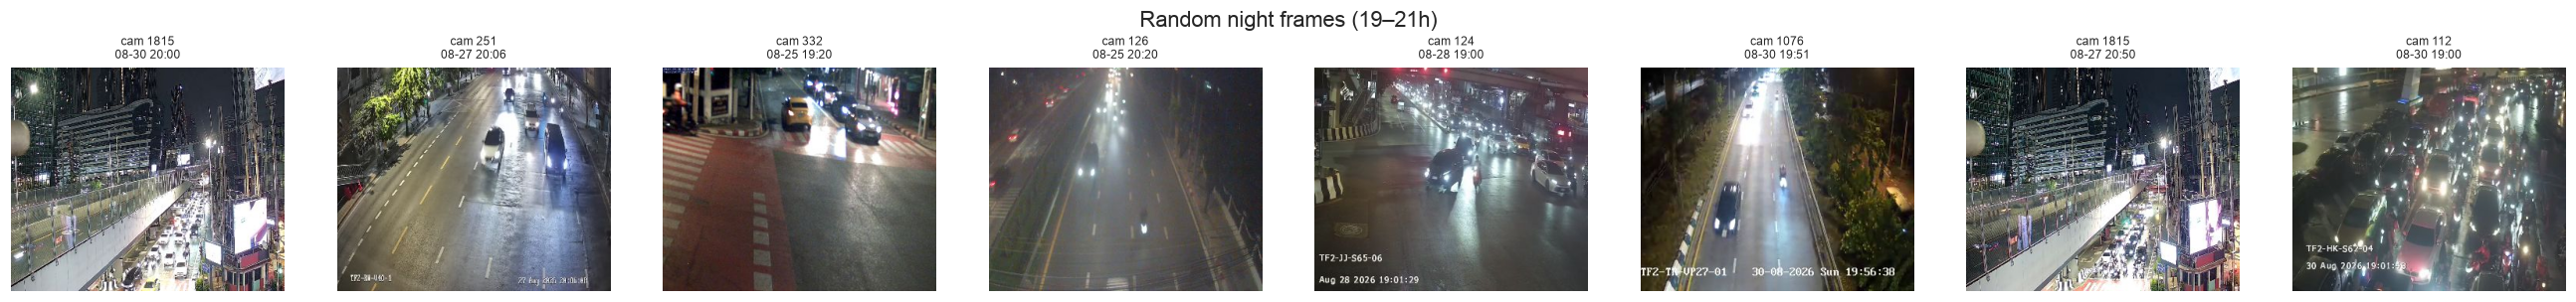

In [16]:
show(v.sample(8, random_state=1), "Random valid frames", 8)
show(v[v.hour >= 19].sample(8, random_state=2), "Random night frames (19–21h)", 8)

## 8. Cleaning rules & output

| Rule | Action |
|---|---|
| 400×266 white / bright_frac>0.9 | drop (camera offline placeholder) |
| 246×205 colour bars | drop (test pattern) |
| dark_frac>0.6 | keep, flag `very_dark` |
| sharpness<100 | keep, flag `blurry` (lower detection confidence) |
| identical ahash to previous frame | keep, flag `stale_repeat` |
| 2026-08-27 06:00–08:50 | flag `system_outage` — exclude from day comparisons |
| cam 395 (348×261) | resize to 352×288 before batching |
| timestamp | use filename time, ignore on-screen clock |

In [17]:
df["system_outage"] = (df.timestamp >= "2026-08-27 06:00") & (df.timestamp < "2026-08-27 09:00")
df["period"] = pd.cut(df.hour, [0, 9, 16, 19, 24], right=False, labels=["morning_peak", "midday", "evening_peak", "night"])
keep_cols = ["path", "camera_id", "camera_name", "location", "timestamp", "date", "hour", "period", "width", "height",
             "file_size", "brightness", "contrast", "saturation", "sharpness", "very_dark", "blurry", "stale_repeat",
             "system_outage", "invalid"]
clean = df.loc[~df.invalid, keep_cols]
clean.to_csv(OUT_DIR / "images_clean.csv", index=False)
print(f"clean: {len(clean):,} / {len(df):,} images ({len(clean)/len(df):.1%}), {clean.camera_id.nunique()} cameras")

clean: 60,782 / 61,319 images (99.1%), 100 cameras


## Key findings

1. **61,319 images, 100 cameras, 7 days (25–31 Aug 2026), 06:00–21:00, every ~10 min.** No corrupt files, no duplicates, filename parsing 100%.
2. **~0.9% invalid**: 504 white placeholder frames (system-wide failures in morning slots, every camera affected 2–10×) + 33 test-pattern frames (cams 432, 1804).
3. **System outage 27-Aug 06:00–08:50** — morning peak of that day missing for 97 cameras.
4. Mixed resolution (4 sizes); cam 395 uses 348×261.
5. On-screen clocks are wrong on several cameras → filename timestamp is the truth.
6. Clear day/night split at ~18:30; night frames darker, less sharp, more glare → expect lower detection accuracy.
7. Camera names truncated & non-unique → key on `camera_id`; geolocation must come from an external source (BMA camera list / scraping) to build the map.

**Next**: run a vehicle detector (e.g. YOLO) on `images_clean.csv` → counts per camera × 10-min → join with weather/rain, holidays, BTS/MRT, Longdo traffic, etc. → dashboard.